# Brazilian E-commerce Sales and Fulfillment Analysis, 2016-2018: Growth, Seasonality, Delivery vs. Estimates

### 1. Initial Exploration & Data Characteristics

* **Q1.1:** What are the data types of all columns in the `customers` table?
* **Q1.2:** What is the overall time range (minimum date and maximum date) during which orders were placed?
* **Q1.3:** What is the total count of distinct cities and states where ordering customers are located?

### 2. In-Depth Exploration & Order Trends

* **Q2.1:** Is there a growing trend in the total number of orders placed Year-over-Year (YoY)?
* **Q2.2:** How do order volumes vary across months of the year (Monthly Seasonality)?
* **Q2.3:** What are the peak order purchase times during different time windows of the day (Dawn, Morning, Afternoon, Night)?

### 3. Evolution of E-Commerce in Brazil

* **Q3.1:** What is the Month-on-Month (MoM) order count distribution across different customer states?
* **Q3.2:** How are unique customers distributed across states in Brazil?

### 4. Impact on Economy: Price & Freight Analysis

* **Q4.1:** What is the percentage increase in total order payment value between 2017 and 2018 for the same period (Jan–Aug)?
* **Q4.2:** What are the total and average order prices per customer state?
* **Q4.3:** What are the total and average freight costs per customer state?

### 5. Delivery Performance & Freight Analysis

* **Q5.1:** What is the delivery duration distribution and the gap between estimated delivery date and actual delivery date?
* **Q5.2:** Which are the top 5 states with the highest and lowest average freight costs?
* **Q5.3:** Which are the top 5 states with the highest (slowest) and lowest (fastest) average delivery times?
* **Q5.4:** Which top 5 states deliver packages fastest relative to their estimated delivery dates?

### 6. Payment Analysis

* **Q6.1:** What is the Month-on-Month order volume distribution across different payment methods?
* **Q6.2:** How are orders distributed by the number of payment installments chosen by customers?


## Setup

In [27]:
%pip install --quiet duckdb pandas matplotlib seaborn ipython

Note: you may need to restart the kernel to use updated packages.


In [28]:
import os
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# ==============================================================================
# CONFIGURATION
# ==============================================================================
DATA_DIR = "assets/dataset"  # Path to your CSV folder
OUTPUT_DIR = "assets/charts"  # Path to save generated charts and tables

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Set global Seaborn & Matplotlib styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})


# ==============================================================================
# FAST DATAFRAME TO IMAGE EXPORTER
# ==============================================================================
def save_df_as_image(df: pd.DataFrame, filepath: str, max_rows: int = 10):
    """Renders top dataframe rows as an image without memory leaks."""
    sub_df = df.head(max_rows).astype(str)

    fig, ax = plt.subplots(
        figsize=(
            max(6, len(sub_df.columns) * 1.8),
            max(1.8, len(sub_df) * 0.35 + 0.6),
        )
    )
    ax.axis("off")

    tbl = ax.table(
        cellText=sub_df.values,
        colLabels=sub_df.columns,
        loc="center",
        cellLoc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1.1, 1.2)

    plt.savefig(filepath, dpi=120, bbox_inches="tight")
    plt.close(fig)  # Prevents Matplotlib memory leaks
    plt.close("all")


# ==============================================================================
# DUCKDB IN-MEMORY SETUP & PRE-TYPING (LOAD ONCE)
# ==============================================================================
con = duckdb.connect(database=":memory:")

csv_tables = [
    "customers",
    "sellers",
    "geolocation",
    "payments",
    "order_items",
    "order_reviews",
    "products",
]

# Load standard tables via Pandas to handle Latin1 encoding flawlessly
for table in csv_tables:
    file_path = os.path.join(DATA_DIR, f"{table}.csv")
    df_temp = pd.read_csv(file_path, encoding="latin1", low_memory=False)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM df_temp")

# Load orders table via Pandas and pre-cast timestamps in DuckDB RAM
orders_path = os.path.join(DATA_DIR, "orders.csv")
df_orders = pd.read_csv(orders_path, encoding="latin1", low_memory=False)

con.execute(
    """
    CREATE TABLE orders AS 
    SELECT 
        order_id, 
        customer_id, 
        order_status,
        TRY_CAST(order_purchase_timestamp AS TIMESTAMP) AS order_purchase_timestamp,
        TRY_CAST(order_approved_at AS TIMESTAMP) AS order_approved_at,
        TRY_CAST(order_delivered_carrier_date AS TIMESTAMP) AS order_delivered_carrier_date,
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP) AS order_delivered_customer_date,
        TRY_CAST(order_estimated_delivery_date AS TIMESTAMP) AS order_estimated_delivery_date
    FROM df_orders;
"""
)

print(
    f"✓ All 8 CSV tables successfully loaded into DuckDB memory from '{DATA_DIR}'.\n"
)

✓ All 8 CSV tables successfully loaded into DuckDB memory from 'assets/dataset'.



## **Q1.1:** What are the data types of all columns in the `customers` table?

,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,customer_unique_id,VARCHAR,YES,None,None,None
2,customer_zip_code_prefix,BIGINT,YES,None,None,None
3,customer_city,VARCHAR,YES,None,None,None
4,customer_state,VARCHAR,YES,None,None,None


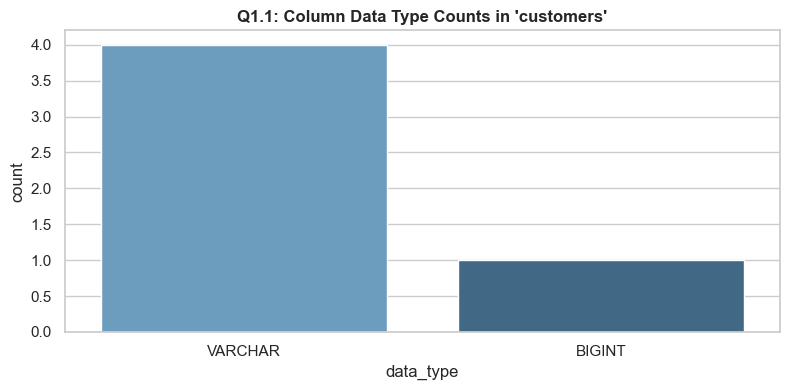

In [29]:
QUERY_Q1_1 = "DESCRIBE SELECT * FROM customers;"

df_1_1 = con.execute(QUERY_Q1_1).df()
display(df_1_1.head(10))
save_df_as_image(df_1_1, f"{OUTPUT_DIR}/table_1_1.jpg")
fig, ax = plt.subplots(figsize=(8, 4))
dtype_counts = df_1_1["column_type"].value_counts().reset_index()
dtype_counts.columns = ["data_type", "count"]
sns.barplot(
    data=dtype_counts,
    x="data_type",
    y="count",
    hue="data_type",
    legend=False,
    palette="Blues_d",
    ax=ax,
)
ax.set_title(
    "Q1.1: Column Data Type Counts in 'customers'",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_1_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")


## **Q1.2:** What is the overall time range (minimum date and maximum date) during which orders were placed?

,min_date,max_date
0,2016-09-04 21:15:19,2018-10-17 17:30:18


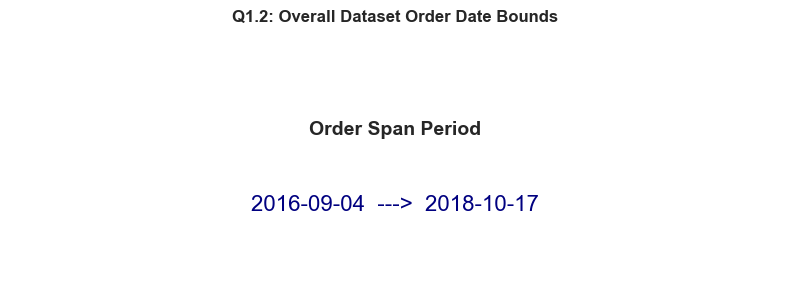

In [30]:
QUERY_Q1_2 = """
    SELECT 
        MIN(order_purchase_timestamp) AS min_date,
        MAX(order_purchase_timestamp) AS max_date
    FROM orders;
"""

df_1_2 = con.execute(QUERY_Q1_2).df()
display(df_1_2.head(10))
save_df_as_image(df_1_2, f"{OUTPUT_DIR}/table_1_2.jpg")
fig, ax = plt.subplots(figsize=(8, 3))
min_d, max_d = (
    str(df_1_2["min_date"].iloc[0])[:10],
    str(df_1_2["max_date"].iloc[0])[:10],
)
ax.text(
    0.5,
    0.6,
    "Order Span Period",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
)
ax.text(
    0.5,
    0.3,
    f"{min_d}  --->  {max_d}",
    ha="center",
    va="center",
    fontsize=16,
    color="navy",
)
ax.axis("off")
ax.set_title(
    "Q1.2: Overall Dataset Order Date Bounds", fontsize=12, fontweight="bold"
)
plt.savefig(f"{OUTPUT_DIR}/chart_1_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q1.3:** What is the total count of distinct cities and states where ordering customers are located?

,city_count,state_count
0,4119,27


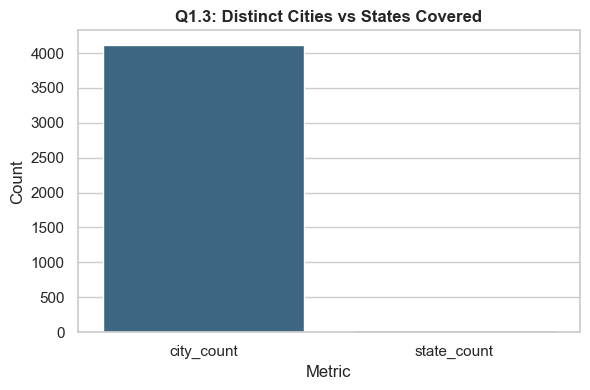

In [31]:
QUERY_Q1_3 = """
    SELECT
        COUNT(DISTINCT customer_city) AS city_count,
        COUNT(DISTINCT customer_state) AS state_count
    FROM customers;
"""

df_1_3 = con.execute(QUERY_Q1_3).df()
display(df_1_3.head(10))
save_df_as_image(df_1_3, f"{OUTPUT_DIR}/table_1_3.jpg")
fig, ax = plt.subplots(figsize=(6, 4))
geo_melted = pd.melt(df_1_3, var_name="Metric", value_name="Count")
sns.barplot(
    data=geo_melted,
    x="Metric",
    y="Count",
    hue="Metric",
    legend=False,
    palette="viridis",
    ax=ax,
)
ax.set_title(
    "Q1.3: Distinct Cities vs States Covered", fontsize=12, fontweight="bold"
)
plt.savefig(f"{OUTPUT_DIR}/chart_1_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q2.1:** Is there a growing trend in the total number of orders placed Year-over-Year (YoY)?

,year,total_orders
0,2016,329
1,2017,45101
2,2018,54011


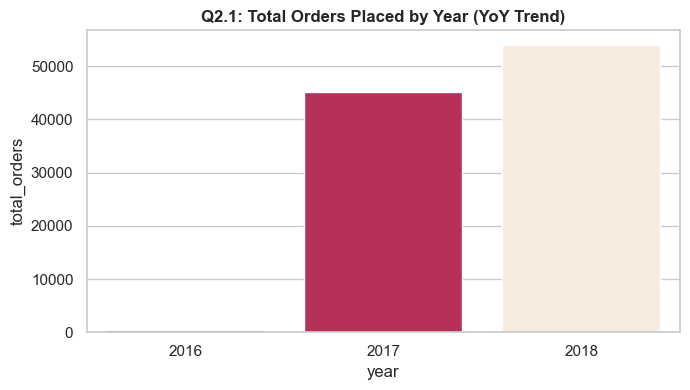

In [32]:
QUERY_Q2_1 = """
    SELECT
        EXTRACT(YEAR FROM order_purchase_timestamp) AS year,
        COUNT(order_id) AS total_orders
    FROM orders
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY year
    ORDER BY year ASC;
"""

df_2_1 = con.execute(QUERY_Q2_1).df()
display(df_2_1.head(10))
save_df_as_image(df_2_1, f"{OUTPUT_DIR}/table_2_1.jpg")
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=df_2_1,
    x="year",
    y="total_orders",
    hue="year",
    legend=False,
    palette="rocket",
    ax=ax,
)
ax.set_title(
    "Q2.1: Total Orders Placed by Year (YoY Trend)",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_2_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q2.2:** How do order volumes vary across months of the year (Monthly Seasonality)?

,month,total_orders
0,1,8069
1,2,8508
2,3,9893
3,4,9343
4,5,10573
5,6,9412
6,7,10318
7,8,10843
8,9,4305
9,10,4959


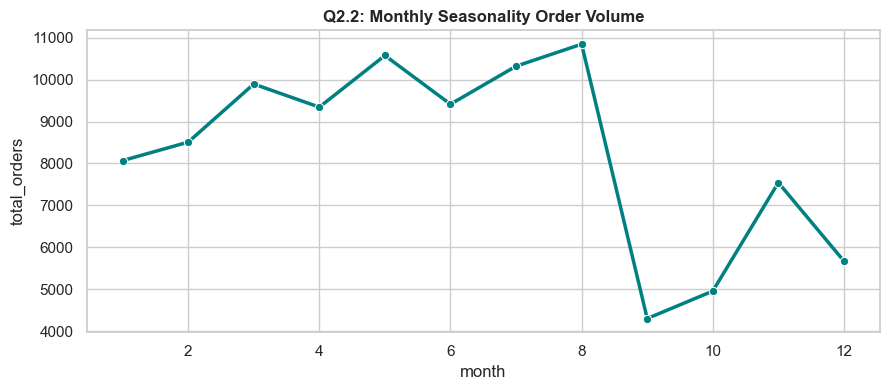

In [33]:
QUERY_Q2_2 = """
    SELECT
        EXTRACT(MONTH FROM order_purchase_timestamp) AS month,
        COUNT(order_id) AS total_orders
    FROM orders
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY month
    ORDER BY month ASC;
"""

df_2_2 = con.execute(QUERY_Q2_2).df()
display(df_2_2.head(10))
save_df_as_image(df_2_2, f"{OUTPUT_DIR}/table_2_2.jpg")
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(
    data=df_2_2,
    x="month",
    y="total_orders",
    marker="o",
    linewidth=2.5,
    color="teal",
    ax=ax,
)
ax.set_title(
    "Q2.2: Monthly Seasonality Order Volume", fontsize=12, fontweight="bold"
)
plt.savefig(f"{OUTPUT_DIR}/chart_2_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q2.3:** What are the peak order purchase times during different time windows of the day (Dawn, Morning, Afternoon, Night)?

,time_of_day,order_count
0,Afternoon,38135
1,Night,28331
2,Morning,27733
3,Dawn,5242


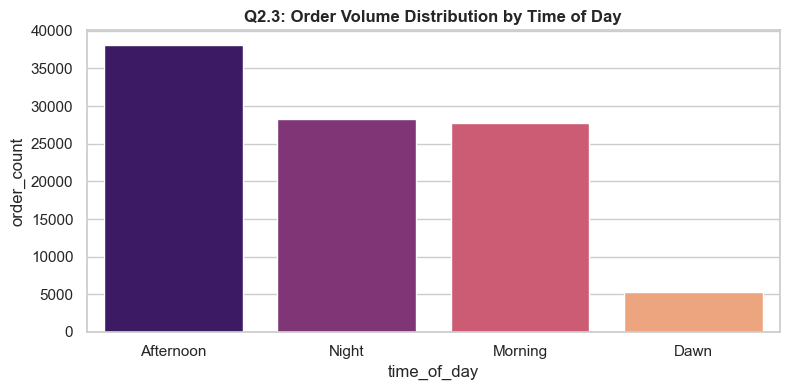

In [34]:
QUERY_Q2_3 = """
    WITH time_of_day_cte AS (
        SELECT
            CASE
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 0 AND 6 THEN 'Dawn'
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 7 AND 12 THEN 'Morning'
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 13 AND 18 THEN 'Afternoon'
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 19 AND 23 THEN 'Night'
            END AS time_of_day
        FROM orders
        WHERE order_purchase_timestamp IS NOT NULL
    )
    SELECT time_of_day, COUNT(*) AS order_count
    FROM time_of_day_cte
    GROUP BY time_of_day
    ORDER BY order_count DESC;
"""

df_2_3 = con.execute(QUERY_Q2_3).df()
display(df_2_3.head(10))
save_df_as_image(df_2_3, f"{OUTPUT_DIR}/table_2_3.jpg")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=df_2_3,
    x="time_of_day",
    y="order_count",
    hue="time_of_day",
    legend=False,
    palette="magma",
    ax=ax,
)
ax.set_title(
    "Q2.3: Order Volume Distribution by Time of Day",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_2_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q3.1:** What is the Month-on-Month (MoM) order count distribution across different customer states?

,customer_state,year_month,order_count
0,RR,2016-09,1
1,RS,2016-09,1
2,SP,2016-09,2
3,AL,2016-10,2
4,BA,2016-10,4
5,CE,2016-10,8
6,DF,2016-10,6
7,ES,2016-10,4
8,GO,2016-10,9
9,MA,2016-10,4


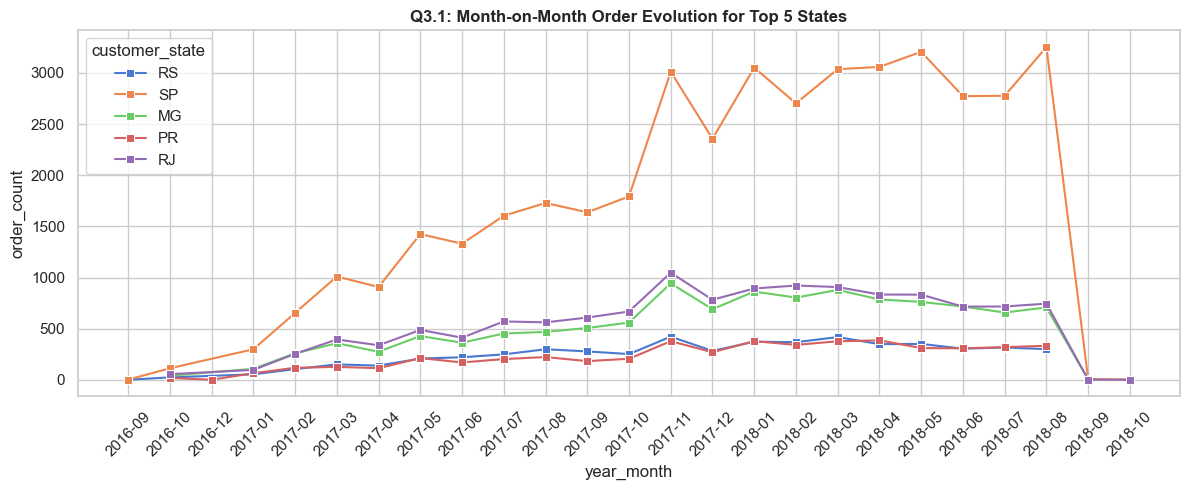

In [35]:
QUERY_Q3_1 = """
    SELECT 
        c.customer_state,
        STRFTIME(o.order_purchase_timestamp, '%Y-%m') AS year_month,
        COUNT(o.order_id) AS order_count
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    WHERE o.order_purchase_timestamp IS NOT NULL
    GROUP BY c.customer_state, year_month
    ORDER BY year_month ASC, c.customer_state ASC;
"""

df_3_1 = con.execute(QUERY_Q3_1).df()
display(df_3_1.head(10))
save_df_as_image(df_3_1, f"{OUTPUT_DIR}/table_3_1.jpg")
top_5_states = (
    df_3_1.groupby("customer_state")["order_count"].sum().nlargest(5).index
)
df_3_1_filtered = df_3_1[df_3_1["customer_state"].isin(top_5_states)]
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=df_3_1_filtered,
    x="year_month",
    y="order_count",
    hue="customer_state",
    marker="s",
    ax=ax,
)
ax.set_title(
    "Q3.1: Month-on-Month Order Evolution for Top 5 States",
    fontsize=12,
    fontweight="bold",
)
plt.xticks(rotation=45)
plt.savefig(f"{OUTPUT_DIR}/chart_3_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q3.2:** How are unique customers distributed across states in Brazil?

,customer_state,total_customers
0,SP,40302
1,RJ,12384
2,MG,11259
3,RS,5277
4,PR,4882
5,SC,3534
6,BA,3277
7,DF,2075
8,ES,1964
9,GO,1952


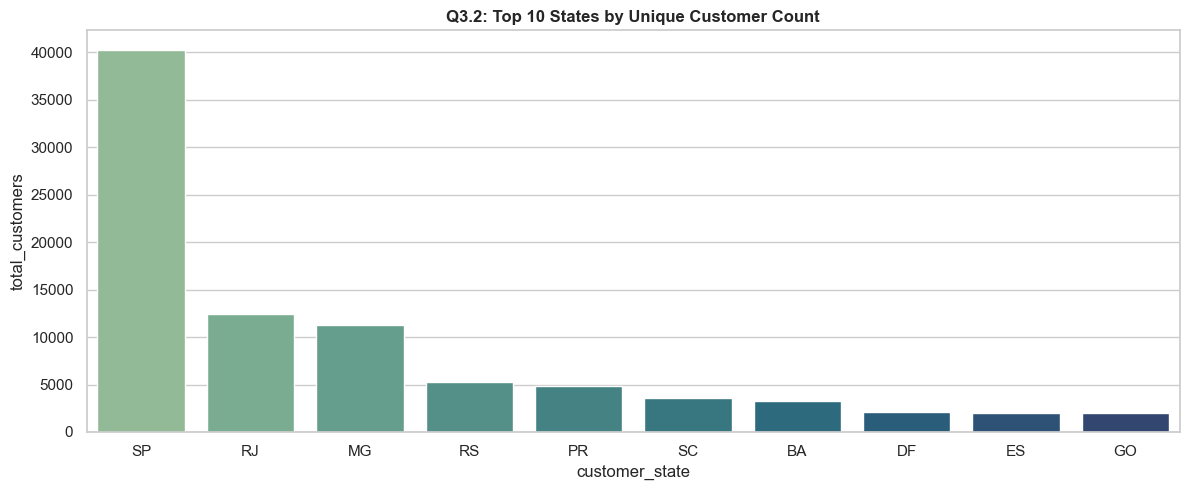

In [36]:
QUERY_Q3_2 = """
    SELECT 
        customer_state,
        COUNT(DISTINCT customer_unique_id) AS total_customers
    FROM customers
    GROUP BY customer_state
    ORDER BY total_customers DESC;
"""

df_3_2 = con.execute(QUERY_Q3_2).df()
display(df_3_2.head(10))
save_df_as_image(df_3_2, f"{OUTPUT_DIR}/table_3_2.jpg")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=df_3_2.head(10),
    x="customer_state",
    y="total_customers",
    hue="customer_state",
    legend=False,
    palette="crest",
    ax=ax,
)
ax.set_title(
    "Q3.2: Top 10 States by Unique Customer Count",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_3_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q4.1:** What is the percentage increase in total order payment value between 2017 and 2018 for the same period (Jan–Aug)?

,total_2017,total_2018,percentage_increase
0,3669022.12,8694733.84,136.98


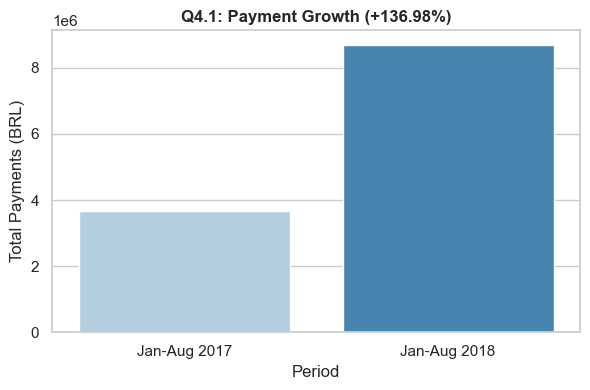

In [37]:
QUERY_Q4_1 = """
    WITH period_payments AS (
        SELECT
            EXTRACT(YEAR FROM o.order_purchase_timestamp) AS order_year,
            p.payment_value
        FROM orders o
        JOIN payments p ON o.order_id = p.order_id
        WHERE EXTRACT(YEAR FROM o.order_purchase_timestamp) IN (2017, 2018)
          AND EXTRACT(MONTH FROM o.order_purchase_timestamp) BETWEEN 1 AND 8
    ),
    aggregated_totals AS (
        SELECT
            SUM(CASE WHEN order_year = 2017 THEN payment_value ELSE 0 END) AS total_2017,
            SUM(CASE WHEN order_year = 2018 THEN payment_value ELSE 0 END) AS total_2018
        FROM period_payments
    )
    SELECT 
        total_2017,
        total_2018,
        ROUND(((total_2018 - total_2017) / NULLIF(total_2017, 0)) * 100, 2) AS percentage_increase
    FROM aggregated_totals;
"""

df_4_1 = con.execute(QUERY_Q4_1).df()
display(df_4_1.head(10))
save_df_as_image(df_4_1, f"{OUTPUT_DIR}/table_4_1.jpg")
fig, ax = plt.subplots(figsize=(6, 4))
p_df = pd.DataFrame(
    {
        "Period": ["Jan-Aug 2017", "Jan-Aug 2018"],
        "Total Payments (BRL)": [
            df_4_1["total_2017"].iloc[0],
            df_4_1["total_2018"].iloc[0],
        ],
    }
)
sns.barplot(
    data=p_df,
    x="Period",
    y="Total Payments (BRL)",
    hue="Period",
    legend=False,
    palette="Blues",
    ax=ax,
)
ax.set_title(
    f"Q4.1: Payment Growth (+{df_4_1['percentage_increase'].iloc[0]}%)",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_4_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q4.2:** What are the total and average order prices per customer state?

,customer_state,total_order_price,avg_order_price
0,SP,5202955.05,109.65
1,RJ,1824092.67,125.12
2,MG,1585308.03,120.75
3,RS,750304.02,120.34
4,PR,683083.76,119.00
5,SC,520553.34,124.65
6,BA,511349.99,134.60
7,DF,302603.94,125.77
8,GO,294591.95,126.27
9,ES,275037.31,121.91


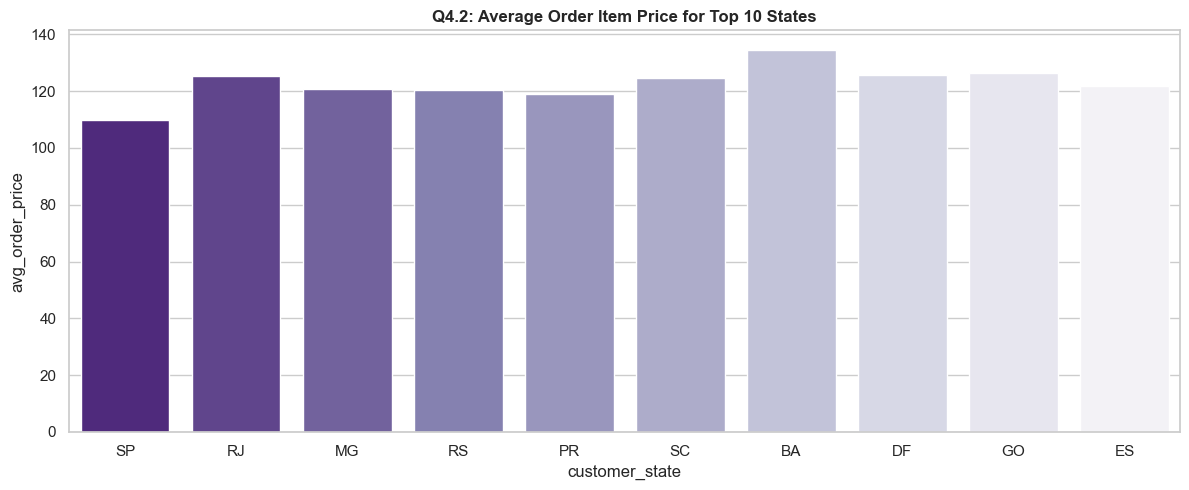

In [38]:
QUERY_Q4_2 = """
    SELECT
        c.customer_state,
        ROUND(SUM(oi.price), 2) AS total_order_price,
        ROUND(AVG(oi.price), 2) AS avg_order_price
    FROM customers c 
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY c.customer_state
    ORDER BY total_order_price DESC;
"""

df_4_2 = con.execute(QUERY_Q4_2).df()
display(df_4_2.head(10))
save_df_as_image(df_4_2, f"{OUTPUT_DIR}/table_4_2.jpg")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=df_4_2.head(10),
    x="customer_state",
    y="avg_order_price",
    hue="customer_state",
    legend=False,
    palette="Purples_r",
    ax=ax,
)
ax.set_title(
    "Q4.2: Average Order Item Price for Top 10 States",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_4_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q4.3:** What are the total and average freight costs per customer state?

,customer_state,total_freight_value,avg_freight_value
0,RR,2235.19,42.98
1,PB,25719.73,42.72
2,RO,11417.38,41.07
3,AC,3686.75,40.07
4,PI,21218.20,39.15
5,MA,31523.77,38.26
6,TO,11732.68,37.25
7,SE,14111.47,36.65
8,AL,15914.59,35.84
9,PA,38699.30,35.83


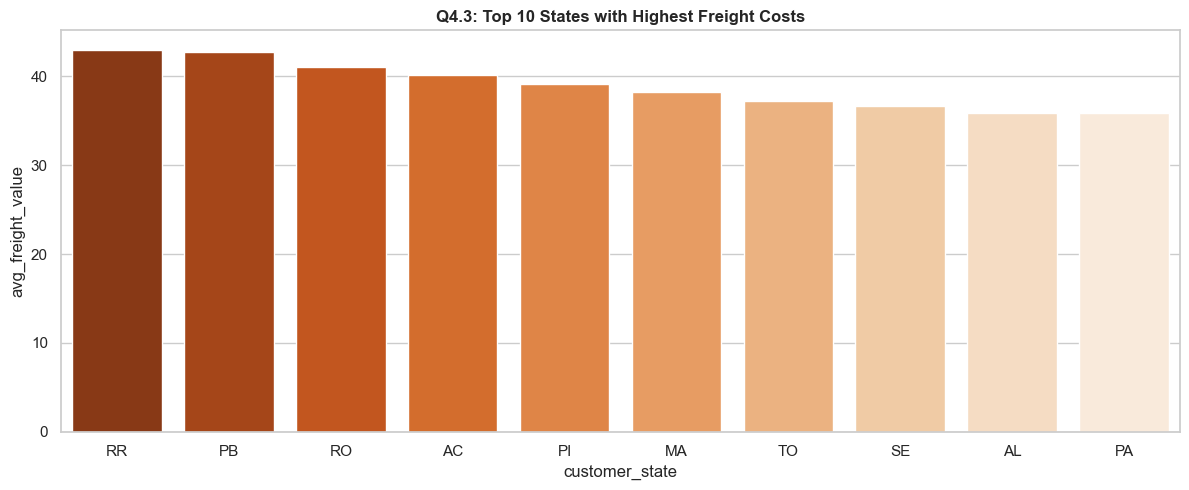

In [39]:
QUERY_Q4_3 = """
    SELECT
        c.customer_state,
        ROUND(SUM(oi.freight_value), 2) AS total_freight_value,
        ROUND(AVG(oi.freight_value), 2) AS avg_freight_value
    FROM customers c 
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY c.customer_state
    ORDER BY avg_freight_value DESC;
"""

df_4_3 = con.execute(QUERY_Q4_3).df()
display(df_4_3.head(10))
save_df_as_image(df_4_3, f"{OUTPUT_DIR}/table_4_3.jpg")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=df_4_3.head(10),
    x="customer_state",
    y="avg_freight_value",
    hue="customer_state",
    legend=False,
    palette="Oranges_r",
    ax=ax,
)
ax.set_title(
    "Q4.3: Top 10 States with Highest Freight Costs",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_4_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q5.1:** What is the delivery duration distribution and the gap between estimated delivery date and actual delivery date?

,order_id,time_to_deliver,diff_estimated_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,8,8
1,53cdb2fc8bc7dce0b6741e2150273451,14,6
2,47770eb9100c2d0c44946d9cf07ec65d,9,18
3,949d5b44dbf5de918fe9c16f97b45f8a,14,13
4,ad21c59c0840e6cb83a9ceb5573f8159,3,10
5,a4591c265e18cb1dcee52889e2d8acc3,17,6
6,6514b8ad8028c9f2cc2374ded245783f,10,12
7,76c6e866289321a7c93b82b54852dc33,10,32
8,e69bfb5eb88e0ed6a785585b27e16dbf,18,7
9,e6ce16cb79ec1d90b1da9085a6118aeb,13,9


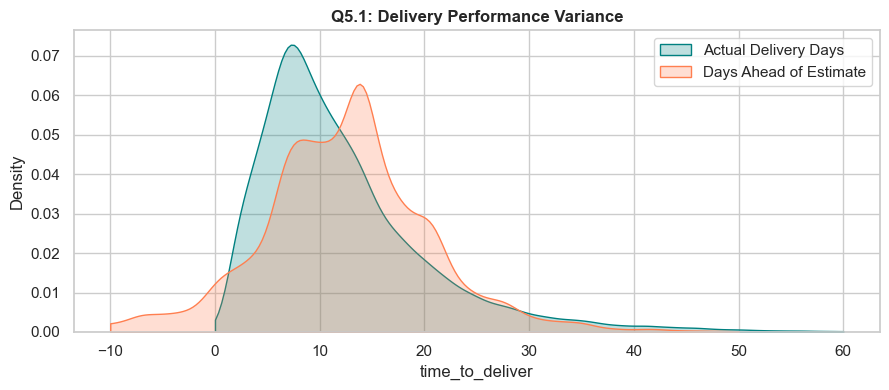

In [40]:
QUERY_Q5_1 = """
    SELECT
        order_id,
        DATE_DIFF('day', order_purchase_timestamp, order_delivered_customer_date) AS time_to_deliver,
        DATE_DIFF('day', order_delivered_customer_date, order_estimated_delivery_date) AS diff_estimated_delivery
    FROM orders
    WHERE order_delivered_customer_date IS NOT NULL AND order_purchase_timestamp IS NOT NULL;
"""

df_5_1 = con.execute(QUERY_Q5_1).df()
display(df_5_1.head(10))
save_df_as_image(df_5_1, f"{OUTPUT_DIR}/table_5_1.jpg")
fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(
    data=df_5_1["time_to_deliver"],
    label="Actual Delivery Days",
    fill=True,
    color="teal",
    clip=(0, 60),
    ax=ax,
)
sns.kdeplot(
    data=df_5_1["diff_estimated_delivery"],
    label="Days Ahead of Estimate",
    fill=True,
    color="coral",
    clip=(-10, 50),
    ax=ax,
)
ax.set_title(
    "Q5.1: Delivery Performance Variance", fontsize=12, fontweight="bold"
)
ax.legend()
plt.savefig(f"{OUTPUT_DIR}/chart_5_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q5.2:** Which are the top 5 states with the highest and lowest average freight costs?

,customer_state,avg_freight,category
0,RR,42.98,Highest 5
1,PB,42.72,Highest 5
2,RO,41.07,Highest 5
3,AC,40.07,Highest 5
4,PI,39.15,Highest 5
5,SP,15.15,Lowest 5
6,PR,20.53,Lowest 5
7,MG,20.63,Lowest 5
8,RJ,20.96,Lowest 5
9,DF,21.04,Lowest 5


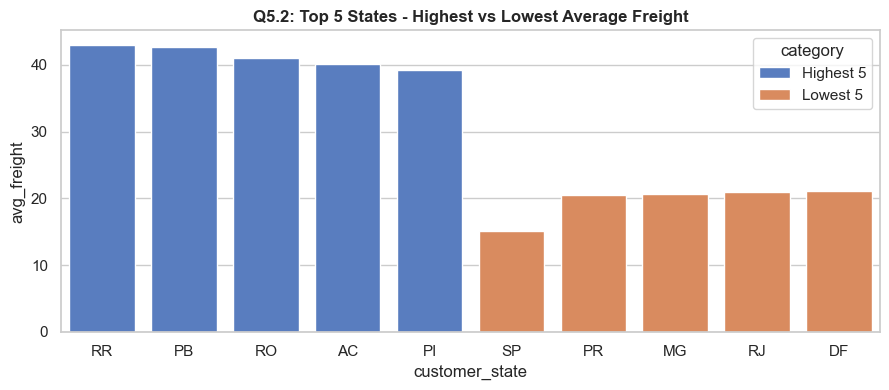

In [41]:
QUERY_Q5_2 = """
    (
        SELECT c.customer_state, ROUND(AVG(oi.freight_value), 2) AS avg_freight, 'Highest 5' AS category
        FROM customers c JOIN orders o ON c.customer_id = o.customer_id JOIN order_items oi ON o.order_id = oi.order_id
        GROUP BY c.customer_state ORDER BY avg_freight DESC LIMIT 5
    )
    UNION ALL
    (
        SELECT c.customer_state, ROUND(AVG(oi.freight_value), 2) AS avg_freight, 'Lowest 5' AS category
        FROM customers c JOIN orders o ON c.customer_id = o.customer_id JOIN order_items oi ON o.order_id = oi.order_id
        GROUP BY c.customer_state ORDER BY avg_freight ASC LIMIT 5
    );
"""

df_5_2 = con.execute(QUERY_Q5_2).df()
display(df_5_2.head(10))
save_df_as_image(df_5_2, f"{OUTPUT_DIR}/table_5_2.jpg")
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=df_5_2,
    x="customer_state",
    y="avg_freight",
    hue="category",
    dodge=False,
    ax=ax,
)
ax.set_title(
    "Q5.2: Top 5 States - Highest vs Lowest Average Freight",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_5_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")


## **Q5.3:** Which are the top 5 states with the highest (slowest) and lowest (fastest) average delivery times?

,customer_state,avg_delivery_days,category
0,RR,29.34,Slowest 5
1,AP,27.18,Slowest 5
2,AM,26.36,Slowest 5
3,AL,24.50,Slowest 5
4,PA,23.73,Slowest 5
5,SP,8.70,Fastest 5
6,PR,11.94,Fastest 5
7,MG,11.95,Fastest 5
8,DF,12.90,Fastest 5
9,SC,14.91,Fastest 5


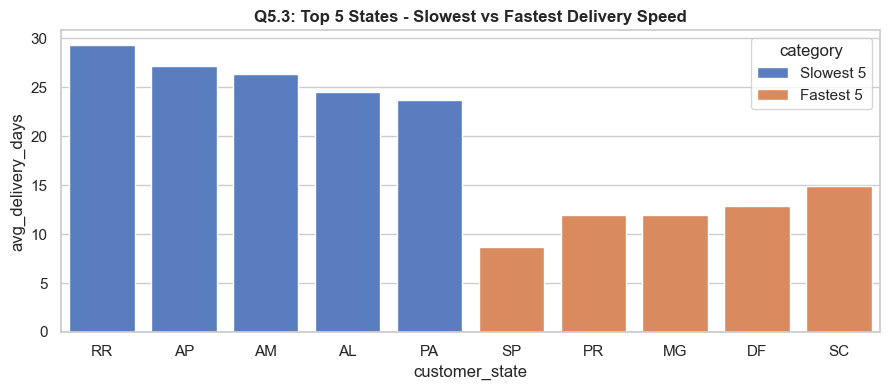

In [42]:
QUERY_Q5_3 = """
    (
        SELECT c.customer_state, ROUND(AVG(DATE_DIFF('day', o.order_purchase_timestamp, o.order_delivered_customer_date)), 2) AS avg_delivery_days, 'Slowest 5' AS category
        FROM customers c JOIN orders o ON c.customer_id = o.customer_id 
        WHERE o.order_delivered_customer_date IS NOT NULL AND o.order_purchase_timestamp IS NOT NULL
        GROUP BY c.customer_state ORDER BY avg_delivery_days DESC LIMIT 5
    )
    UNION ALL
    (
        SELECT c.customer_state, ROUND(AVG(DATE_DIFF('day', o.order_purchase_timestamp, o.order_delivered_customer_date)), 2) AS avg_delivery_days, 'Fastest 5' AS category
        FROM customers c JOIN orders o ON c.customer_id = o.customer_id 
        WHERE o.order_delivered_customer_date IS NOT NULL AND o.order_purchase_timestamp IS NOT NULL
        GROUP BY c.customer_state ORDER BY avg_delivery_days ASC LIMIT 5
    );
"""

df_5_3 = con.execute(QUERY_Q5_3).df()
display(df_5_3.head(10))
save_df_as_image(df_5_3, f"{OUTPUT_DIR}/table_5_3.jpg")
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=df_5_3,
    x="customer_state",
    y="avg_delivery_days",
    hue="category",
    dodge=False,
    ax=ax,
)
ax.set_title(
    "Q5.3: Top 5 States - Slowest vs Fastest Delivery Speed",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_5_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q5.4:** Which top 5 states deliver packages fastest relative to their estimated delivery dates?

,customer_state,days_ahead_of_estimate
0,AC,20.73
1,RO,20.10
2,AP,19.69
3,AM,19.57
4,RR,17.29


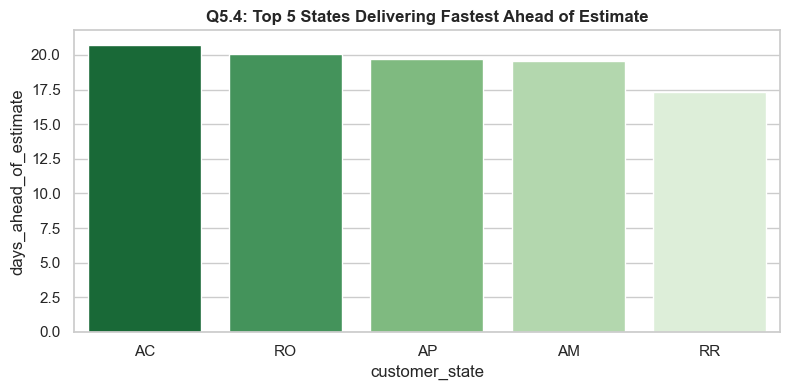

In [43]:
QUERY_Q5_4 = """
    SELECT
        c.customer_state,
        ROUND(AVG(DATE_DIFF('day', o.order_delivered_customer_date, o.order_estimated_delivery_date)), 2) AS days_ahead_of_estimate
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    WHERE o.order_delivered_customer_date IS NOT NULL AND o.order_estimated_delivery_date IS NOT NULL
    GROUP BY c.customer_state
    HAVING days_ahead_of_estimate > 0
    ORDER BY days_ahead_of_estimate DESC
    LIMIT 5;
"""

df_5_4 = con.execute(QUERY_Q5_4).df()
display(df_5_4.head(10))
save_df_as_image(df_5_4, f"{OUTPUT_DIR}/table_5_4.jpg")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=df_5_4,
    x="customer_state",
    y="days_ahead_of_estimate",
    hue="customer_state",
    legend=False,
    palette="Greens_r",
    ax=ax,
)
ax.set_title(
    "Q5.4: Top 5 States Delivering Fastest Ahead of Estimate",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_5_4.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q6.1:** What is the Month-on-Month order volume distribution across different payment methods?

,year_month,payment_type,total_orders
0,2016-09,credit_card,3
1,2016-10,UPI,63
2,2016-10,credit_card,253
3,2016-10,debit_card,2
4,2016-10,voucher,11
5,2016-12,credit_card,1
6,2017-01,UPI,197
7,2017-01,credit_card,582
8,2017-01,debit_card,9
9,2017-01,voucher,33


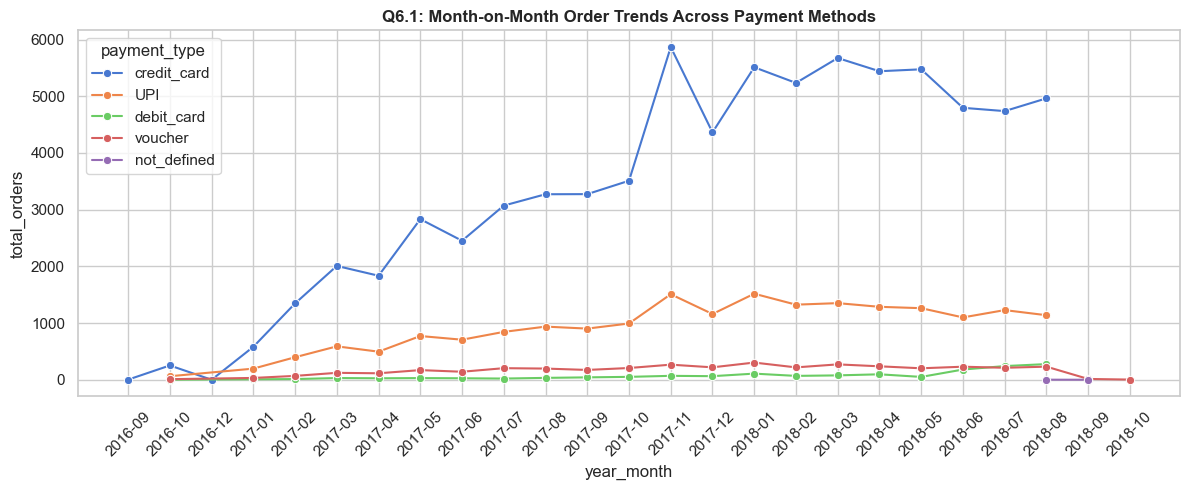

In [44]:
QUERY_Q6_1 = """
    SELECT
        STRFTIME(o.order_purchase_timestamp, '%Y-%m') AS year_month,
        p.payment_type,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM orders o
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_purchase_timestamp IS NOT NULL
    GROUP BY year_month, p.payment_type
    ORDER BY year_month ASC, p.payment_type ASC;
"""

df_6_1 = con.execute(QUERY_Q6_1).df()
display(df_6_1.head(10))
save_df_as_image(df_6_1, f"{OUTPUT_DIR}/table_6_1.jpg")
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=df_6_1,
    x="year_month",
    y="total_orders",
    hue="payment_type",
    marker="o",
    ax=ax,
)
ax.set_title(
    "Q6.1: Month-on-Month Order Trends Across Payment Methods",
    fontsize=12,
    fontweight="bold",
)
plt.xticks(rotation=45)
plt.savefig(f"{OUTPUT_DIR}/chart_6_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## **Q6.2:** How are orders distributed by the number of payment installments chosen by customers?

,payment_installments,total_orders
0,1,49060
1,2,12389
2,3,10443
3,4,7088
4,5,5234
5,6,3916
6,7,1623
7,8,4253
8,9,644
9,10,5315


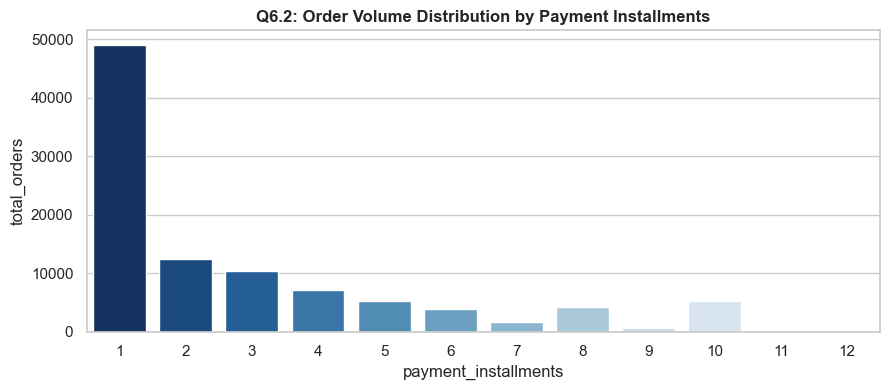

In [45]:
QUERY_Q6_2 = """
    SELECT
        payment_installments,
        COUNT(DISTINCT order_id) AS total_orders
    FROM payments
    WHERE payment_installments > 0 AND payment_installments <= 12
    GROUP BY payment_installments
    ORDER BY payment_installments ASC;
"""

df_6_2 = con.execute(QUERY_Q6_2).df()
display(df_6_2.head(10))
save_df_as_image(df_6_2, f"{OUTPUT_DIR}/table_6_2.jpg")
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=df_6_2,
    x="payment_installments",
    y="total_orders",
    hue="payment_installments",
    legend=False,
    palette="Blues_r",
    ax=ax,
)
ax.set_title(
    "Q6.2: Order Volume Distribution by Payment Installments",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(f"{OUTPUT_DIR}/chart_6_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")